# Dala Market — E-commerce Sales Analysis (2024–2025)

**Author:** Medet Makhambetkhan · **Tools:** Python (pandas, matplotlib), SQL (SQLite)

Dala Market is a fictional online electronics & home-tech store in Kazakhstan that launched in January 2024.
Management asked four questions:

1. **How is the business growing**, and how much of it depends on promo seasons?
2. **Which customers and channels are actually valuable** — not just who brings orders, but who comes back?
3. **Which categories make money** once discounts, costs and returns are counted?
4. **Where are we losing customers** — delivery, returns, discounts?

> Data is synthetic (generated by `scripts/generate_data.py` with a fixed seed) but modelled on real e-commerce
> behaviour: seasonality (11.11, Black Friday, New Year, 8 March), regional delivery times, channel-dependent loyalty,
> and deliberate data-quality problems in the raw files. All amounts are in **KZT**.

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, IMG = ROOT / "data/raw", ROOT / "data/processed", ROOT / "images"
IMG.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

# Validated categorical palette (fixed order) + chart ink
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10.5, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "figure.dpi": 110,
})
mln = mtick.FuncFormatter(lambda x, _: f"{x/1e6:,.0f}M")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data quality check & cleaning

The raw export has the usual problems. The cleaning logic lives in `scripts/clean_data.py`; here we show *what* it fixes.

In [2]:
raw_c = pd.read_csv(RAW / "customers.csv")
raw_i = pd.read_csv(RAW / "order_items.csv")
issues = pd.Series({
    "Duplicate customer rows": raw_c.duplicated().sum(),
    "Duplicate order-item rows": raw_i.duplicated().sum(),
    "Customers with missing city": raw_c["city"].isna().sum(),
    "Impossible birth years (<1940 or >2010)": (~raw_c["birth_year"].between(1940, 2010)).sum(),
    "Distinct city spellings (raw)": raw_c["city"].nunique(),
}, name="count")
issues.to_frame()

,count
Duplicate customer rows,25
Duplicate order-item rows,180
Customers with missing city,110
Impossible birth years (<1940 or >2010),16
Distinct city spellings (raw),22


In [3]:
# Inconsistent spellings of the same city (e.g. the old name 'Nur-Sultan' for Astana)
raw_c["city"].value_counts().loc[lambda s: ~s.index.isin(
    ["Almaty","Astana","Shymkent","Karaganda","Aktobe","Atyrau","Pavlodar",
     "Ust-Kamenogorsk","Kostanay","Taraz","Aktau","Kyzylorda"])]

city
ALMATY             40
Shimkent           37
 Almaty            36
Nur-Sultan         34
almaty             31
Karagandy          30
ASTANA             28
astana             22
Ust Kamenogorsk     8
Oskemen             7
Name: count, dtype: int64

In [4]:
customers = pd.read_csv(PROC / "customers.csv", parse_dates=["signup_date"])
products  = pd.read_csv(PROC / "products.csv")
orders    = pd.read_csv(PROC / "orders.csv", parse_dates=["order_date"])
items     = pd.read_csv(PROC / "order_items.csv")
print("Clean city values:", customers["city"].nunique(), "| rows:",
      {n: len(d) for n, d in [("customers", customers), ("products", products), ("orders", orders), ("items", items)]})

# One analytical table: order lines enriched with order, product and customer attributes
sales = (items.merge(orders, on="order_id")
              .merge(products[["product_id", "category", "brand"]], on="product_id")
              .merge(customers[["customer_id", "city", "acquisition_channel"]], on="customer_id"))
sales["profit"] = sales["net_revenue"] - sales["cogs"]
sales["month"] = sales["order_date"].dt.to_period("M")
done = sales[sales["status"] == "delivered"]          # revenue is counted on delivered orders only
done.head(3)

Clean city values: 13 | rows: {'customers': 12000, 'products': 160, 'orders': 26341, 'items': 40448}


,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,gross_revenue,discount_amount,net_revenue,cogs,...,payment_method,delivery_days,review_score,promo_code,category,brand,city,acquisition_channel,profit,month
0,1,O000001,P0134,1,139990,0.0,139990,0.0,"139,990.0",115841,...,Installments 0-0-12,2.0,NaN,NaN,Gaming,Razer,Almaty,Paid Search,"24,149.0",2024-01
1,2,O000001,P0060,1,91990,0.0,91990,0.0,"91,990.0",55583,...,Installments 0-0-12,2.0,NaN,NaN,Audio,Xiaomi,Almaty,Paid Search,"36,407.0",2024-01
2,3,O000001,P0016,1,426990,0.0,426990,0.0,"426,990.0",361580,...,Installments 0-0-12,2.0,NaN,NaN,Smartphones,Honor,Almaty,Paid Search,"65,410.0",2024-01


## 2. Headline KPIs

In [5]:
kpi = done.groupby(done["order_date"].dt.year).agg(
    revenue=("net_revenue", "sum"), profit=("profit", "sum"),
    orders=("order_id", "nunique"), customers=("customer_id", "nunique"))
kpi["aov"] = kpi["revenue"] / kpi["orders"]
kpi["margin_%"] = 100 * kpi["profit"] / kpi["revenue"]
kpi.loc["YoY growth %"] = 100 * (kpi.iloc[1] / kpi.iloc[0] - 1)
kpi.style.format("{:,.1f}")

,revenue,profit,orders,customers,aov,margin_%
order_date,,,,,,
2024,"1,623,996,469.0","289,093,489.0","9,231.0","5,270.0","175,928.6",17.8
2025,"2,487,822,644.0","452,391,941.0","14,477.0","8,132.0","171,846.6",18.2
YoY growth %,53.2,56.5,56.8,54.3,-2.3,2.2


**Revenue grew +53% to 2.49 bn KZT in 2025**, driven entirely by more customers (+54% active buyers) — the average order
value actually slipped ~2% to ~172k KZT, as more orders came through discount campaigns. Gross margin is thin (~18%) because two low-margin categories — smartphones and laptops — make up ~62% of revenue.

## 3. Growth & seasonality

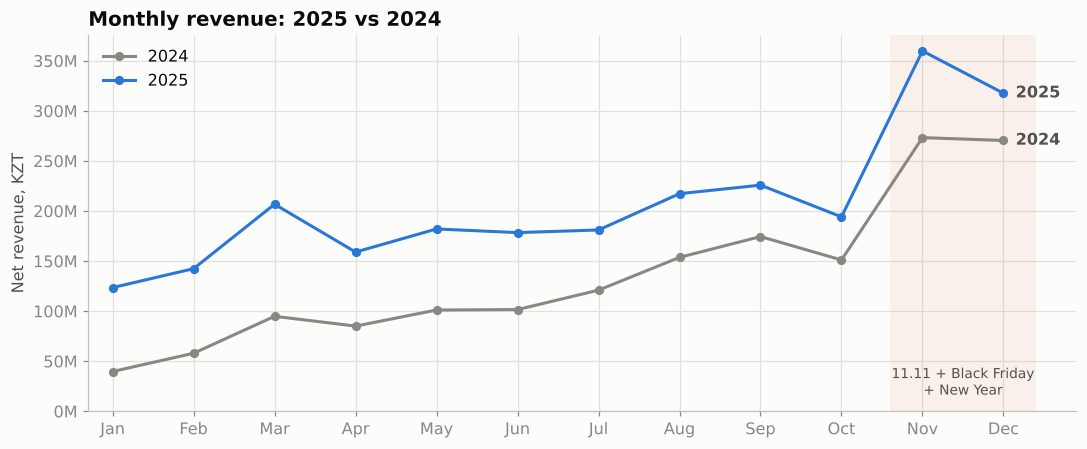

In [6]:
m = done.groupby("month")["net_revenue"].sum()
m.index = m.index.to_timestamp()
fig, ax = plt.subplots(figsize=(10, 4.2))
for yr, col in [(2024, MUTED), (2025, BLUE)]:
    s = m[m.index.year == yr]
    ax.plot(s.index.month, s.values, color=col, lw=2, marker="o", ms=5, label=str(yr))
    ax.annotate(str(yr), (12, s.values[-1]), xytext=(8, 0), textcoords="offset points",
                color=INK2, va="center", fontweight="bold")
ax.axvspan(10.6, 12.4, color=ORANGE, alpha=0.08, lw=0)
ax.text(11.5, 12e6, "11.11 + Black Friday\n+ New Year", ha="center", va="bottom", color=INK2, fontsize=9)
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.yaxis.set_major_formatter(mln); ax.set_ylabel("Net revenue, KZT")
ax.set_xlim(0.7, 12.9); ax.set_ylim(0)
ax.set_title("Monthly revenue: 2025 vs 2024")
ax.legend(loc="upper left")
save(fig, "01_monthly_revenue")

In [7]:
share_q4 = m[m.index.month.isin([11, 12])].groupby(m[m.index.month.isin([11, 12])].index.year).sum() / m.groupby(m.index.year).sum()
print("Share of annual revenue made in Nov–Dec:", (100*share_q4).round(1).to_dict())
yoy = (m[m.index.year == 2025].values / m[m.index.year == 2024].values - 1) * 100
print("YoY growth by month, 2025 %:", {k: int(v) for k, v in zip(range(1, 13), yoy.round(0))})

Share of annual revenue made in Nov–Dec: {2024: 33.5, 2025: 27.2}
YoY growth by month, 2025 %: {1: 211, 2: 146, 3: 118, 4: 87, 5: 80, 6: 76, 7: 50, 8: 41, 9: 29, 10: 29, 11: 32, 12: 17}


**Nov–Dec alone generate 27–34% of annual revenue.** March (8 March gifts) and Aug–Sep (back-to-school,
phone launches) are smaller secondary peaks. Planning stock, couriers and support around Q4 is the single biggest operational lever.

YoY growth is **normalising**: +100–200% in early 2025 (the store was only a few months old) down to **+17–32% in Q4 2025**.
From 2026 growth will have to come from retention and AOV, not just from the launch effect.

## 4. Category profitability

In [8]:
cat = sales.groupby("category").apply(lambda d: pd.Series({
    "revenue": d.loc[d.status == "delivered", "net_revenue"].sum(),
    "profit": d.loc[d.status == "delivered", "profit"].sum(),
    "return_rate_%": 100 * d.loc[d.status == "returned", "order_id"].nunique() / d["order_id"].nunique(),
}), include_groups=False)
cat["margin_%"] = 100 * cat["profit"] / cat["revenue"]
cat["revenue_share_%"] = 100 * cat["revenue"] / cat["revenue"].sum()
cat["profit_share_%"] = 100 * cat["profit"] / cat["profit"].sum()
cat = cat.sort_values("revenue", ascending=False)
cat

,revenue,profit,return_rate_%,margin_%,revenue_share_%,profit_share_%
category,,,,,,
Smartphones,"1,348,583,338.0","168,519,932.0",7.6,12.5,32.8,22.7
Laptops,"1,193,843,983.0","121,815,517.0",9.7,10.2,29.0,16.4
Home Appliances,"483,015,000.0","108,888,509.0",8.0,22.5,11.7,14.7
Gaming,"348,900,146.0","61,858,419.0",7.2,17.7,8.5,8.3
Audio,"241,205,247.0","81,655,871.0",7.0,33.9,5.9,11.0
Smart Home,"205,048,829.0","76,918,654.0",6.9,37.5,5.0,10.4
Accessories,"188,071,649.0","86,364,790.0",5.7,45.9,4.6,11.6
Beauty Tech,"103,150,921.0","35,463,738.0",7.4,34.4,2.5,4.8


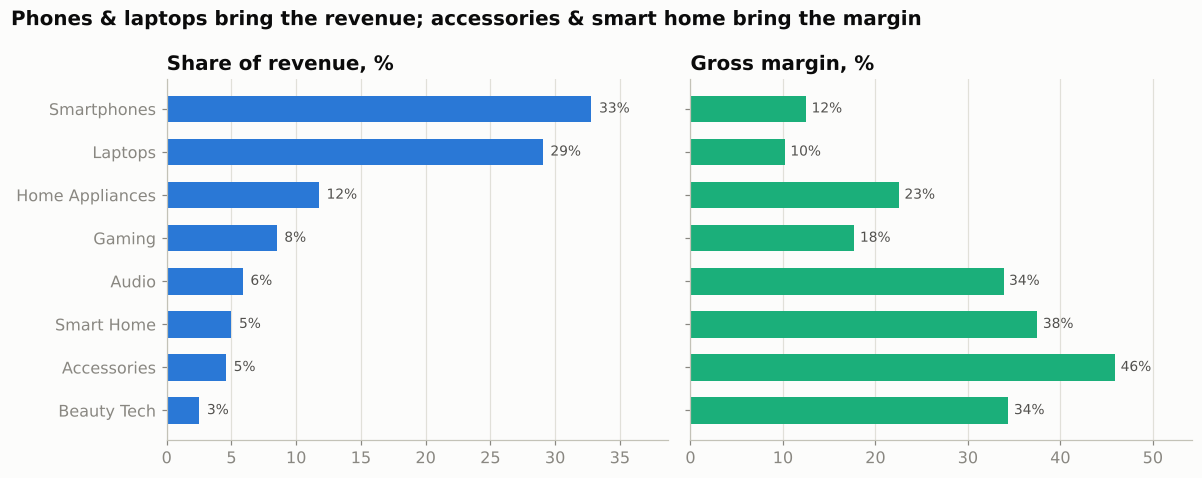

In [9]:
c = cat.sort_values("revenue")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
axes[0].barh(c.index, c["revenue_share_%"], color=BLUE, height=0.62)
axes[0].set_title("Share of revenue, %")
axes[1].barh(c.index, c["margin_%"], color=AQUA, height=0.62)
axes[1].set_title("Gross margin, %")
for ax, col in zip(axes, ["revenue_share_%", "margin_%"]):
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(c[col]):
        ax.text(v + 0.6, y, f"{v:.0f}%", va="center", color=INK2, fontsize=9)
    ax.set_xlim(0, c[col].max() * 1.18)
fig.suptitle("Phones & laptops bring the revenue; accessories & smart home bring the margin",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
save(fig, "02_category_revenue_vs_margin")

Smartphones + laptops = **62% of revenue but only 39% of gross profit** (margins 10–13%). Accessories, smart home and
audio earn 34–46% margin. Cross-selling an accessory with every phone/laptop order is the cheapest way to lift margin.

## 5. Customers: retention & cohorts

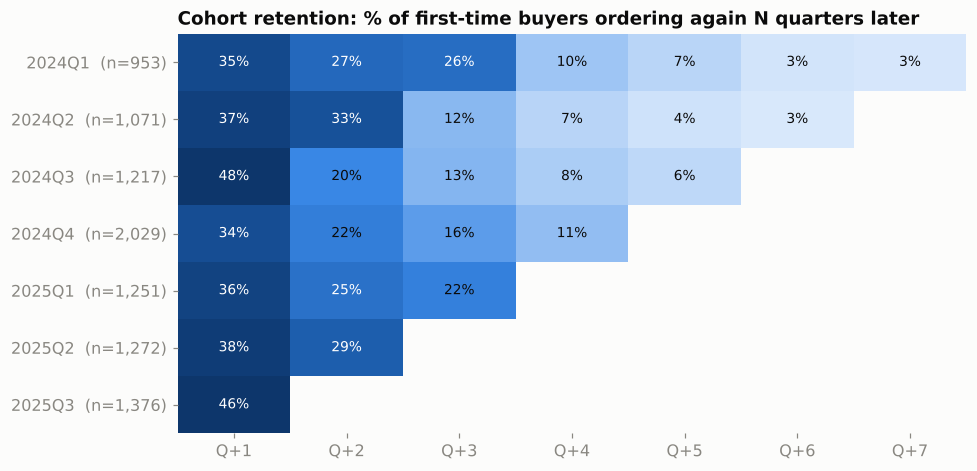

In [10]:
first = done.groupby("customer_id")["order_date"].min().dt.to_period("Q").rename("cohort")
act = done[["customer_id", "order_date"]].drop_duplicates().join(first, on="customer_id")
act["q_n"] = (act["order_date"].dt.to_period("Q") - act["cohort"]).apply(lambda x: x.n)
coh = act.groupby(["cohort", "q_n"])["customer_id"].nunique().unstack()
coh = coh[coh[1].notna()]   # drop the last cohort (no next quarter observed yet)
retention = coh.div(coh[0], axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 4.4))
vals = retention.iloc[:, 1:].to_numpy()
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blue", ["#eef5fe", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
im = ax.imshow(vals, cmap=cmap, vmin=0, vmax=40, aspect="auto")
for (i, j), v in np.ndenumerate(vals):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if v > 22 else INK)
ax.set_xticks(range(vals.shape[1]), [f"Q+{k}" for k in range(1, vals.shape[1] + 1)])
ax.set_yticks(range(len(retention)), [f"{p}  (n={int(n):,})" for p, n in zip(retention.index.astype(str), coh[0])])
ax.grid(False); ax.spines[:].set_visible(False)
ax.set_title("Cohort retention: % of first-time buyers ordering again N quarters later", fontsize=12)
save(fig, "03_cohort_retention")

**35–48% of new buyers come back in the next quarter**, but retention falls to 12–26% by Q+3 and to ~10% or less a year later. The first 90 days after the first order are where loyalty is won or lost — a post-purchase email/CRM flow is the obvious play.

## 6. Acquisition channels — who brings *valuable* customers?

In [11]:
cust_orders = orders.merge(customers[["customer_id", "acquisition_channel"]], on="customer_id")
ch = customers.groupby("acquisition_channel").size().rename("customers").to_frame()
ch["orders_per_customer"] = cust_orders.groupby("acquisition_channel").size() / ch["customers"]
ch["return_rate_%"] = 100 * cust_orders.groupby("acquisition_channel")["status"].apply(lambda s: (s == "returned").mean())
ch["profit_per_customer"] = done.groupby("acquisition_channel")["profit"].sum() / ch["customers"]
ch = ch.sort_values("profit_per_customer", ascending=False)
ch

,customers,orders_per_customer,return_rate_%,profit_per_customer
acquisition_channel,,,,
Email,1191,2.8,6.5,"81,128.3"
Referral,1825,2.7,5.3,"76,008.7"
Organic Search,2850,2.4,6.4,"69,006.2"
Paid Search,2447,1.9,7.4,"54,439.9"
Instagram,2089,1.9,7.2,"53,579.7"
TikTok,1598,1.5,11.6,"40,260.2"


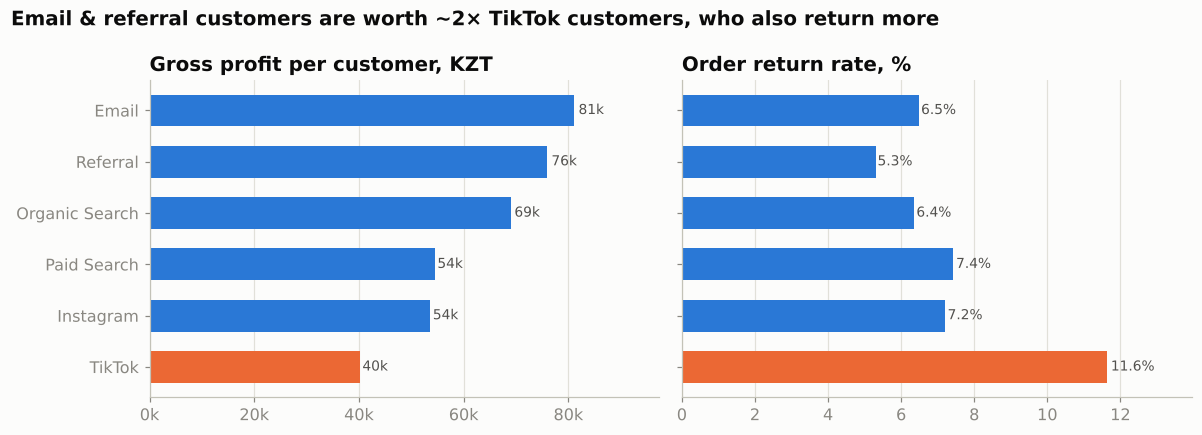

In [12]:
c = ch.sort_values("profit_per_customer")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = [ORANGE if i == "TikTok" else BLUE for i in c.index]
axes[0].barh(c.index, c["profit_per_customer"], color=colors, height=0.62)
axes[0].set_title("Gross profit per customer, KZT")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}k"))
axes[1].barh(c.index, c["return_rate_%"], color=colors, height=0.62)
axes[1].set_title("Order return rate, %")
for ax, col, fmt in [(axes[0], "profit_per_customer", lambda v: f"{v/1e3:,.0f}k"), (axes[1], "return_rate_%", lambda v: f"{v:.1f}%")]:
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(c[col]):
        ax.text(v * 1.01, y, fmt(v), va="center", color=INK2, fontsize=9)
    ax.set_xlim(0, c[col].max() * 1.2)
fig.suptitle("Email & referral customers are worth ~2× TikTok customers, who also return more",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
save(fig, "04_channel_quality")

TikTok brings young customers cheaply, but they place **1.5 orders vs 2.8 for email**, and return **11.6% of orders**
(vs 5.3% for referral). Budget decisions should be made on **profit per customer (≈ LTV)**, not on first-order CAC.

## 7. RFM segmentation

In [13]:
snapshot = done["order_date"].max() + pd.Timedelta(days=1)
rfm = done.groupby("customer_id").agg(
    recency=("order_date", lambda d: (snapshot - d.max()).days),
    frequency=("order_id", "nunique"), monetary=("net_revenue", "sum"))
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = rfm["frequency"].clip(upper=5)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(r):
    if r.R >= 4 and r.F >= 4: return "Champions"
    if r.R >= 3 and r.F >= 3: return "Loyal"
    if r.R >= 4 and r.F <= 2: return "New / Promising"
    if r.R == 3 and r.F <= 2: return "Need Attention"
    if r.R <= 2 and (r.F >= 3 or r.M >= 4): return "At Risk (high value)"
    return "Hibernating"

rfm["segment"] = rfm.apply(segment, axis=1)
seg = rfm.groupby("segment").agg(customers=("R", "size"), avg_recency=("recency", "mean"),
                                 avg_orders=("frequency", "mean"), revenue=("monetary", "sum"))
seg["customers_%"] = 100 * seg["customers"] / seg["customers"].sum()
seg["revenue_%"] = 100 * seg["revenue"] / seg["revenue"].sum()
seg = seg.sort_values("revenue", ascending=False)
rfm.reset_index().to_csv(PROC / "rfm_segments.csv", index=False)
seg

,customers,avg_recency,avg_orders,revenue,customers_%,revenue_%
segment,,,,,,
At Risk (high value),2059,418.8,2.6,"1,226,069,168.0",17.9,29.8
Loyal,1615,122.1,3.3,"908,712,461.0",14.1,22.1
New / Promising,3199,44.6,1.4,"776,448,419.0",27.8,18.9
Champions,609,50.8,4.5,"486,295,820.0",5.3,11.8
Need Attention,1474,193.6,1.5,"395,262,312.0",12.8,9.6
Hibernating,2531,456.5,1.4,"319,030,933.0",22.0,7.8


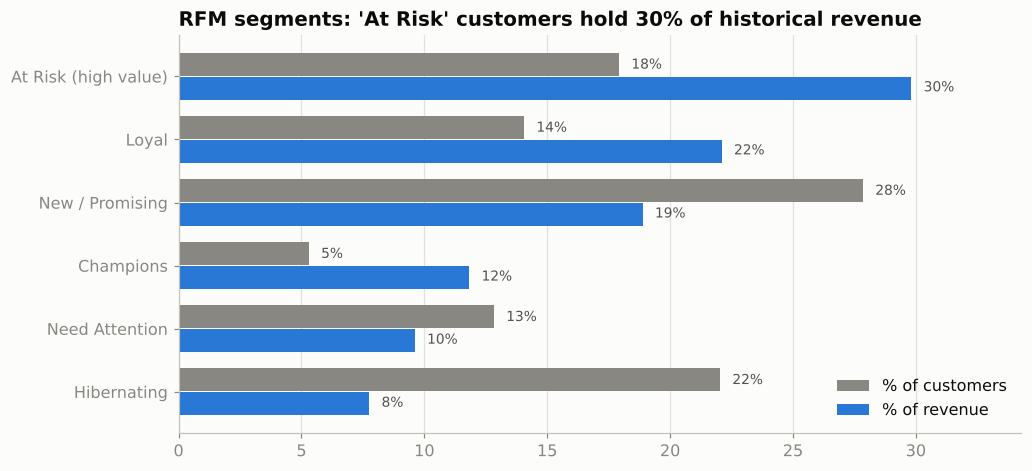

In [14]:
s = seg.sort_values("revenue_%")
y = np.arange(len(s)); h = 0.36
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.barh(y + h/2 + 0.01, s["customers_%"], h, color=MUTED, label="% of customers")
ax.barh(y - h/2 - 0.01, s["revenue_%"], h, color=BLUE, label="% of revenue")
for i, (cu, rv) in enumerate(zip(s["customers_%"], s["revenue_%"])):
    ax.text(cu + 0.5, i + h/2, f"{cu:.0f}%", va="center", fontsize=9, color=INK2)
    ax.text(rv + 0.5, i - h/2, f"{rv:.0f}%", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, s.index); ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(s["customers_%"].max(), s["revenue_%"].max()) * 1.15)
ax.legend(loc="lower right")
ax.set_title("RFM segments: 'At Risk' customers hold 30% of historical revenue")
save(fig, "05_rfm_segments")

**18% of customers are "At Risk (high value)"** — they bought often or spent a lot, but haven't ordered in over a year.
They account for **~30% of all revenue**. A targeted win-back campaign here is worth more than any new-customer campaign.

## 8. Operations: delivery speed → satisfaction → returns

In [15]:
o = orders[orders["status"] != "cancelled"].copy()
o["delivery"] = pd.cut(o["delivery_days"], [0, 2, 4, 99], labels=["1–2 days", "3–4 days", "5+ days"])
dl = o.groupby("delivery", observed=True).agg(
    orders=("order_id", "size"), avg_review=("review_score", "mean"),
    low_review_pct=("review_score", lambda s: 100 * (s.dropna() <= 2).mean()),
    return_rate_pct=("status", lambda s: 100 * (s == "returned").mean()))
dl

,orders,avg_review,low_review_pct,return_rate_pct
delivery,,,,
1–2 days,9723,4.4,1.6,6.6
3–4 days,10329,4.1,3.6,6.6
5+ days,5493,3.4,16.9,9.4


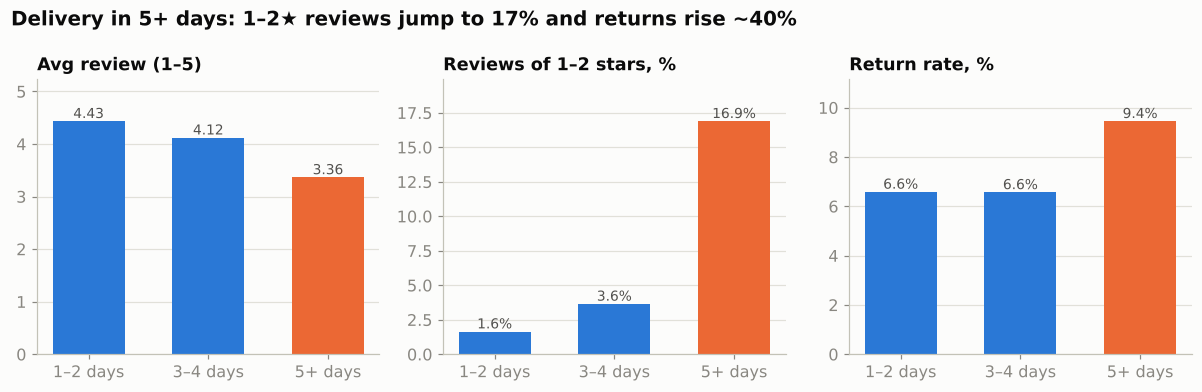

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, col, title, fmt in [
    (axes[0], "avg_review", "Avg review (1–5)", "{:.2f}"),
    (axes[1], "low_review_pct", "Reviews of 1–2 stars, %", "{:.1f}%"),
    (axes[2], "return_rate_pct", "Return rate, %", "{:.1f}%")]:
    cols = [BLUE, BLUE, ORANGE]
    ax.bar(dl.index.astype(str), dl[col], color=cols, width=0.6)
    ax.set_title(title, fontsize=11.5); ax.grid(axis="x", visible=False)
    for x, v in enumerate(dl[col]):
        ax.text(x, v, fmt.format(v), ha="center", va="bottom", fontsize=9, color=INK2)
    ax.set_ylim(0, dl[col].max() * 1.18)
fig.suptitle("Delivery in 5+ days: 1–2★ reviews jump to 17% and returns rise ~40%",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
save(fig, "06_delivery_vs_satisfaction")

In [17]:
city_tbl = (done.groupby("city").agg(revenue=("net_revenue", "sum"))
            .join(orders.merge(customers[["customer_id", "city"]], on="customer_id")
                  .query("status == 'delivered'").groupby("city")
                  .agg(avg_delivery=("delivery_days", "mean"), avg_review=("review_score", "mean"))))
city_tbl["revenue_share_%"] = 100 * city_tbl["revenue"] / city_tbl["revenue"].sum()
city_tbl.sort_values("revenue", ascending=False)

,revenue,avg_delivery,avg_review,revenue_share_%
city,,,,
Almaty,"1,209,495,076.0",2.1,4.4,29.4
Astana,"872,027,243.0",2.1,4.4,21.2
Shymkent,"390,950,128.0",3.1,4.2,9.5
Karaganda,"268,883,890.0",4.1,4.0,6.5
Aktobe,"202,901,119.0",4.1,4.0,4.9
Atyrau,"198,789,592.0",5.1,3.7,4.8
Pavlodar,"183,161,187.0",4.1,4.1,4.5
Kostanay,"168,158,638.0",4.1,4.1,4.1
Ust-Kamenogorsk,"164,678,594.0",5.1,3.8,4.0


Almaty and Astana (≈51% of revenue) get 2-day delivery and ~4.4★ reviews. Western and eastern cities —
**Aktau, Atyrau, Kyzylorda, Ust-Kamenogorsk** — wait 5–6 days and rate us ~3.5–3.8★. A regional pickup point or courier partner
in the west would protect ~15% of revenue.

## 9. Are discounts paying off?

In [18]:
pr = done.assign(promo=done["promo_code"].fillna("(none)")).groupby("promo").agg(
    orders=("order_id", "nunique"), revenue=("net_revenue", "sum"),
    discount=("discount_amount", "sum"), profit=("profit", "sum"))
pr["aov"] = pr["revenue"] / pr["orders"]
pr["margin_%"] = 100 * pr["profit"] / pr["revenue"]
pr = pr.sort_values("margin_%", ascending=False)
pr

,orders,revenue,discount,profit,aov,margin_%
promo,,,,,,
(none),17770,"3,196,105,280.0",0.0,"644,118,931.0","179,859.6",20.2
WELCOME5,1322,"230,414,506.0","12,127,794.0","37,149,641.0","174,292.4",16.1
NEWYEAR,2406,"359,456,765.0","40,596,405.0","42,712,593.0","149,400.2",11.9
MARCH8,702,"103,558,361.0","14,805,539.0","10,087,867.0","147,519.0",9.7
BLACKFRIDAY,1267,"183,660,258.0","39,403,022.0","6,157,802.0","144,956.8",3.4
SALE1111,241,"38,623,943.0","7,984,277.0","1,258,596.0","160,265.3",3.3


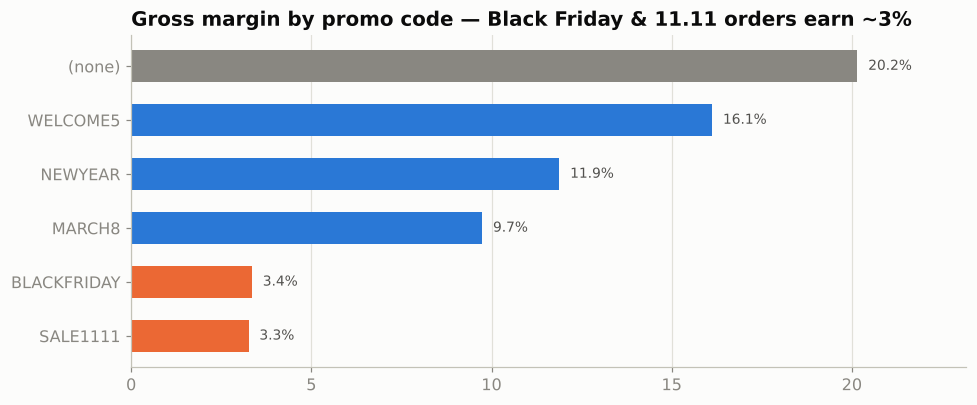

In [19]:
p = pr.sort_values("margin_%")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(p.index, p["margin_%"], color=[MUTED if i == "(none)" else (ORANGE if v < 5 else BLUE) for i, v in zip(p.index, p["margin_%"])], height=0.6)
for y, v in enumerate(p["margin_%"]):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, p["margin_%"].max() * 1.15); ax.grid(axis="y", visible=False)
ax.set_title("Gross margin by promo code — Black Friday & 11.11 orders earn ~3%")
save(fig, "07_promo_margin")

Full-price orders earn a 20% margin. **BLACKFRIDAY (3.4%) and SALE1111 (3.3%) orders are nearly break-even** — a 15–25%
discount on phones and laptops (10–13% margin) wipes out profit. Discounts should be capped by category margin (e.g. deep
discounts only on accessories/smart home, bundles instead of % off on phones).

## 10. Summary & recommendations

| # | Finding | Recommendation | Expected impact |
|---|---------|----------------|-----------------|
| 1 | Revenue **+53% YoY** (2.49 bn KZT), driven by new customers; AOV −2%; YoY growth slowing to ~20–30% | Grow AOV with bundles & accessory cross-sell at checkout | +5–8% AOV |
| 2 | Nov–Dec = **27–34%** of annual revenue | Plan inventory, couriers and support capacity for Q4 from September | Fewer stock-outs, faster peak delivery |
| 3 | Phones/laptops = 62% of revenue at 10–13% margin; BF/11.11 margin ≈ **3%** | Cap discount % by category margin; push high-margin categories in promos | +2–3 pp gross margin |
| 4 | Only 35–48% of buyers return next quarter; ~10% after a year | 90-day post-purchase CRM flow (email, accessories, reviews) | Higher repeat rate |
| 5 | **"At Risk" segment = 30% of revenue**, inactive > 1 year | Personalised win-back campaign | Recover part of lapsed revenue |
| 6 | Email/referral customers worth **~2×** TikTok's; TikTok returns 11.6% | Shift budget toward referral programme; judge channels by profit per customer | Better ROI on marketing spend |
| 7 | 5+ day delivery → 17% bad reviews, 9.4% returns | Regional courier / pickup points in the West (Aktau, Atyrau) | Better reviews and fewer returns |